<a href="https://colab.research.google.com/github/HelalMeftah/-/blob/main/Cars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'saudi-arabia-used-cars-dataset' dataset.
Original shape: (8248, 15)
Columns: ['Link', 'Make', 'Type', 'Year', 'Origin', 'Color', 'Options', 'Engine_Size', 'Fuel_Type', 'Gear_Type', 'Condition', 'Mileage', 'Region', 'Price', 'Negotiable']
Link            object
Make            object
Type            object
Year             int64
Origin          object
Color           object
Options         object
Engine_Size    float64
Fuel_Type       object
Gear_Type       object
Condition       object
Mileage          int64
Region          object
Price           object
Negotiable        bool
dtype: object
Numeric: ['Year', 'Mileage', 'Engine_Size']
Categorical: ['Make', 'Origin', 'Color', 'Options', 'Fuel_Type', 'Gear_Type', 'Region', 'Negotiable']
Shape after cleaning: (4321, 15)


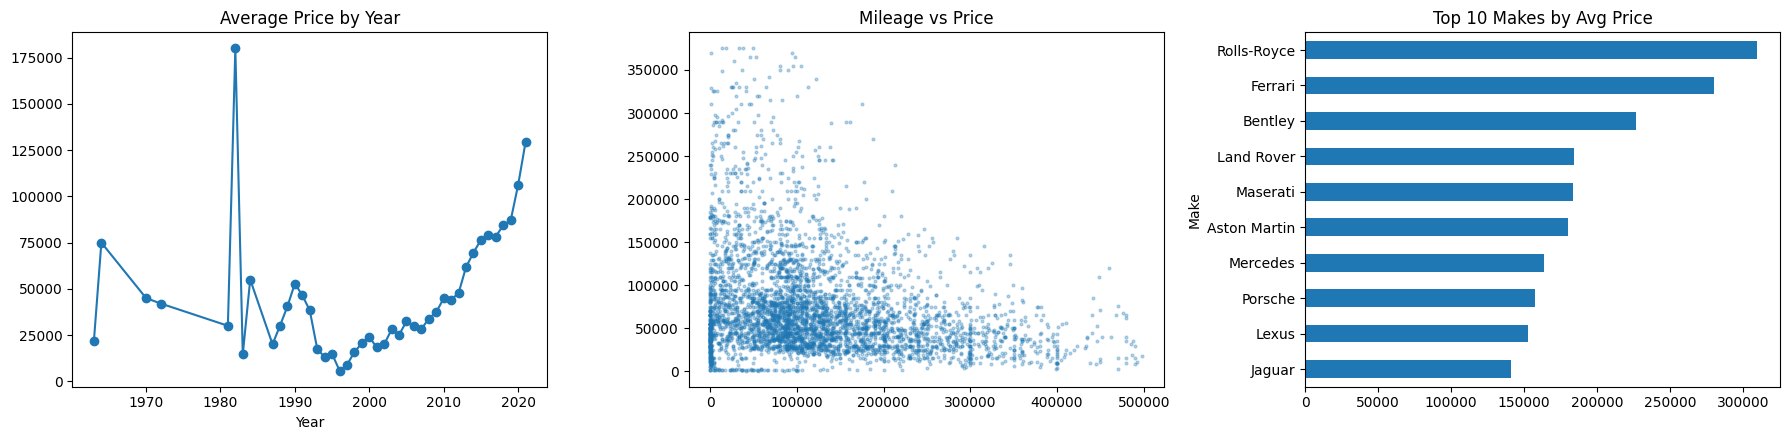

            Model  MAE (SAR)    R2
          XGBoost      17305 0.758
    Random Forest      17963 0.689
Linear Regression      23161 0.639
Best model: XGBoost


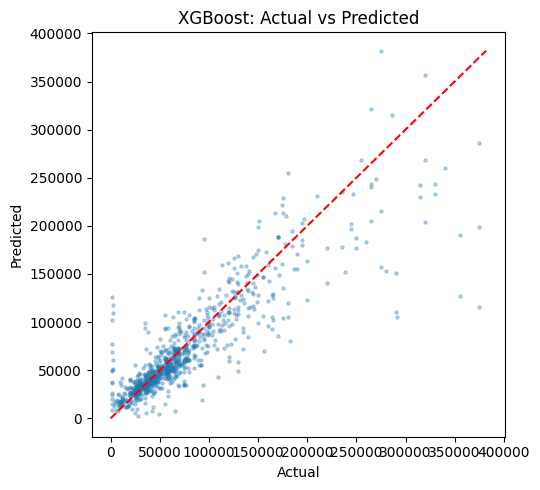

KeyboardInterrupt: Interrupted by user

In [7]:
# ============================================================
# Saudi Used Cars Price Prediction - End-to-End (ONE cell)
# ============================================================
GITHUB_USER = "YOUR_USERNAME"        # your GitHub username
REPO_NAME   = "saudi-used-cars-price"
PUSH_TO_GITHUB = True                # False = run without pushing
# ============================================================

!pip -q install kagglehub xgboost streamlit tabulate

import os, json, glob, joblib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")

# ---------- 0) Project folders ----------
for d in ["notebooks", "models", "images"]:
    os.makedirs(f"{REPO_NAME}/{d}", exist_ok=True)

# ---------- 1) Load data ----------
path = kagglehub.dataset_download("turkibintalib/saudi-arabia-used-cars-dataset")
df = pd.read_csv(glob.glob(f"{path}/**/*.csv", recursive=True)[0])
print("Original shape:", df.shape)

df.columns = [str(c).strip().replace(" ", "_") for c in df.columns]
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
print("Columns:", df.columns.tolist())
print(df.dtypes)

# ---------- 2) Auto-detect columns ----------
lower = {c.lower(): c for c in df.columns}
PRICE = lower.get("price")
if PRICE is None:
    raise ValueError(f"No Price column. Found: {df.columns.tolist()}")

YEAR    = lower.get("year")
MILEAGE = lower.get("mileage")
ENGINE  = lower.get("engine_size") or lower.get("enginesize")

NUM_NAMES = ["year", "mileage", "engine_size", "enginesize", "cylinders", "doors", "seats"]
num_cols = [lower[n] for n in NUM_NAMES if n in lower]

def to_num(s):
    # "45,000 SAR" -> 45000 ; "Negotiable" -> NaN
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True),
                         errors="coerce")

for c in num_cols + [PRICE]:
    df[c] = to_num(df[c])

for c in df.select_dtypes("number").columns:
    if c != PRICE and c not in num_cols and df[c].nunique() > 20:
        num_cols.append(c)

cat_cols = [c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
            if c not in num_cols and c != PRICE and 2 <= df[c].nunique() <= 300]

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

# ---------- 3) Cleaning ----------
df = df.drop_duplicates()
df = df.dropna(subset=num_cols + [PRICE])
df = df[df[PRICE] > 0]
if MILEAGE:
    df = df[(df[MILEAGE] > 0) & (df[MILEAGE] < 500000)]
if ENGINE:
    df = df[df[ENGINE] > 0]
df = df[df[PRICE] < df[PRICE].quantile(0.99)]
for c in cat_cols:
    df[c] = df[c].fillna("Unknown").astype(str)
print("Shape after cleaning:", df.shape)

# ---------- 4) EDA ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
if YEAR:
    df.groupby(YEAR)[PRICE].mean().plot(ax=ax[0], marker="o")
    ax[0].set_title("Average Price by Year")
if MILEAGE:
    ax[1].scatter(df[MILEAGE], df[PRICE], s=4, alpha=.3)
    ax[1].set_title("Mileage vs Price")
if "Make" in df.columns:
    df.groupby("Make")[PRICE].mean().nlargest(10).sort_values().plot.barh(ax=ax[2])
    ax[2].set_title("Top 10 Makes by Avg Price")
plt.tight_layout()
plt.savefig(f"{REPO_NAME}/images/eda.png", dpi=130)
plt.show()

# ---------- 5) Preprocessing + models ----------
X, y = df[num_cols + cat_cols], df[PRICE]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cat_cols),
])

def build(reg):
    return TransformedTargetRegressor(
        regressor=Pipeline([("pre", pre), ("model", reg)]),
        func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, random_state=42),
}

results, fitted = [], {}
for name, reg in models.items():
    m = build(reg).fit(X_tr, y_tr)
    p = m.predict(X_te)
    results.append({"Model": name,
                    "MAE (SAR)": round(mean_absolute_error(y_te, p)),
                    "R2": round(r2_score(y_te, p), 3)})
    fitted[name] = m

res = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
print(res.to_string(index=False))
best_name = res.loc[0, "Model"]
best = fitted[best_name]
print("Best model:", best_name)

pred = best.predict(X_te)
plt.figure(figsize=(5.5, 5))
plt.scatter(y_te, pred, s=5, alpha=.3)
lim = [0, max(y_te.max(), pred.max())]
plt.plot(lim, lim, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title(f"{best_name}: Actual vs Predicted")
plt.tight_layout()
plt.savefig(f"{REPO_NAME}/images/actual_vs_pred.png", dpi=130)
plt.show()

# ---------- 6) Save model + app metadata ----------
joblib.dump(best, f"{REPO_NAME}/models/model.pkl", compress=3)
meta = {
    "num": {c: {"min": float(df[c].min()), "max": float(df[c].max()),
                "median": float(df[c].median())} for c in num_cols},
    "cat": {c: sorted(df[c].unique().tolist()) for c in cat_cols},
}
json.dump(meta, open(f"{REPO_NAME}/models/meta.json", "w"), ensure_ascii=False)
res.to_csv(f"{REPO_NAME}/models/results.csv", index=False)

# ---------- 7) Streamlit app ----------
app_code = '''import streamlit as st, pandas as pd, joblib, json

st.set_page_config(page_title="Saudi Used Cars Price", page_icon="🚗")
model = joblib.load("models/model.pkl")
meta = json.load(open("models/meta.json"))

st.title("Saudi Used Car Price Predictor")
cols = st.columns(2)
row, i = {}, 0

for c, options in meta["cat"].items():
    row[c] = cols[i % 2].selectbox(c.replace("_", " "), options)
    i += 1

for c, r in meta["num"].items():
    row[c] = cols[i % 2].number_input(
        c.replace("_", " "), float(r["min"]), float(r["max"]), float(r["median"]))
    i += 1

if st.button("Predict"):
    price = model.predict(pd.DataFrame([row]))[0]
    st.success(f"Estimated price: {price:,.0f} SAR")
'''
open(f"{REPO_NAME}/app.py", "w").write(app_code)

open(f"{REPO_NAME}/requirements.txt", "w").write(
    "pandas\nnumpy\nscikit-learn\nxgboost\njoblib\nstreamlit\nmatplotlib\n")

# ---------- 8) README ----------
readme = f"""# Saudi Used Cars Price Prediction

End-to-end machine learning project that predicts used car prices in Saudi Arabia,
from data cleaning to an interactive Streamlit app.

## Dataset
Saudi Arabia Used Cars Dataset (Kaggle): turkibintalib/saudi-arabia-used-cars-dataset

## Pipeline
1. Cleaning: text to numbers, duplicates, zero prices, outliers
2. EDA: price vs year, mileage, make
3. Preprocessing: ColumnTransformer (StandardScaler + OneHotEncoder) inside a Pipeline
4. Models: Linear Regression, Random Forest, XGBoost (log-transformed target)
5. Deployment: Streamlit app

## Results
{res.to_markdown(index=False)}

Best model: **{best_name}**

![EDA](images/eda.png)
![Actual vs Predicted](images/actual_vs_pred.png)

## Run the app
    pip install -r requirements.txt
    streamlit run app.py

## Author
{GITHUB_USER}
"""
open(f"{REPO_NAME}/README.md", "w").write(readme)

# ---------- 9) Push to GitHub ----------
if PUSH_TO_GITHUB:
    from getpass import getpass
    token = getpass("GitHub Personal Access Token: ")
    os.chdir(REPO_NAME)
    !git init -q
    !git config user.name "{GITHUB_USER}"
    !git config user.email "{GITHUB_USER}@users.noreply.github.com"
    !git add .
    !git commit -q -m "Saudi used cars price prediction"
    !git branch -M main
    !git remote add origin https://{token}@github.com/{GITHUB_USER}/{REPO_NAME}.git
    !git push -u origin main
    !git remote set-url origin https://github.com/{GITHUB_USER}/{REPO_NAME}.git
    print(f"Done: https://github.com/{GITHUB_USER}/{REPO_NAME}")